# MScFE 652 – Portfolio Management  
## Group Work Project #1: Portfolio Optimization & Fama-French 5-Factor Analysis  

**Student:** Portfolio Management Team  
**Institution:** WorldQuant University  
**Date:** February 11, 2026  

---

### Project Overview
This notebook implements a comprehensive portfolio analysis framework covering:

1. Markowitz Mean-Variance Optimization for 10 assets (with and without constraints)  
2. Constrained Portfolio Optimization with weight limits  
3. Fama-French 5-Factor Model Analysis with OLS and robust regression  
4. Monte Carlo Simulation vs Hard Optimization comparison  
5. Out-of-sample Performance Testing over a 3-month period  

**Data Period:** July 1, 2023 – June 30, 2025 (In-Sample)  
**Test Period:** July 1 – September 30, 2025 (Out-of-Sample)  
**Assets:** TSLA, WMT, BAC, GS, LLY, MRK, GOOG, META, AAPL, XOM  


**Environment Setup**

In [ ]:
# Install and import libraries
!pip install yfinance cvxpy statsmodels

import pandas as pd
import numpy as np
import yfinance as yf
import cvxpy as cp
import matplotlib.pyplot as plt
import statsmodels.api as sm

np.random.seed(42)
pd.set_option("display.max_columns", None)
plt.style.use("seaborn-v0_8-darkgrid")


**Data Acquisition**

In [ ]:

# Asset list
assets = ["TSLA","WMT","BAC","GS","LLY","MRK","GOOG","META","AAPL","XOM"]

# Date ranges
start_date_in, end_date_in = "2023-07-01", "2025-06-30"
start_date_test, end_date_test = "2025-07-01", "2025-09-30"

# Download data
data_in = yf.download(assets, start=start_date_in, end=end_date_in, progress=False)
data_test = yf.download(assets, start=start_date_test, end=end_date_test, progress=False)

# Diagnostic printout
print("Columns returned (in-sample):", data_in.columns)

# If MultiIndex (e.g., ('Adj Close','TSLA')), flatten it
if isinstance(data_in.columns, pd.MultiIndex):
    data_in.columns = ['_'.join(col).strip() for col in data_in.columns.values]
    data_test.columns = ['_'.join(col).strip() for col in data_test.columns.values]

# Select Adjusted Close columns (using 'Close' since auto_adjust=True makes 'Close' adjusted)
adj_close_in = data_in.filter(like="Close")
adj_close_test = data_test.filter(like="Close")

# Rename columns for clarity
# The columns are now like 'Close_AAPL', so we replace 'Close_' with '' and append '_AdjClose'
adj_close_in.columns = [col.replace("Close_", "") + "_AdjClose" for col in adj_close_in.columns]
adj_close_test.columns = [col.replace("Close_", "") + "_AdjClose" for col in adj_close_test.columns]

# Compute returns
returns_in = adj_close_in.pct_change().dropna()
returns_test = adj_close_test.pct_change().dropna()

# Risk-free rate (^IRX)
rf_data = yf.download("^IRX", start=start_date_in, end=end_date_in, progress=False)["Close"]
rf_daily = (rf_data/100/252).mean() if not rf_data.empty else 0.00005
rf_annual = rf_daily * 252


/tmp/ipython-input-4082114684.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data_in = yf.download(assets, start=start_date_in, end=end_date_in, progress=False)
/tmp/ipython-input-4082114684.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data_test = yf.download(assets, start=start_date_test, end=end_date_test, progress=False)


Columns returned (in-sample): MultiIndex([( 'Close', 'AAPL'),
            ( 'Close',  'BAC'),
            ( 'Close', 'GOOG'),
            ( 'Close',   'GS'),
            ( 'Close',  'LLY'),
            ( 'Close', 'META'),
            ( 'Close',  'MRK'),
            ( 'Close', 'TSLA'),
            ( 'Close',  'WMT'),
            ( 'Close',  'XOM'),
            (  'High', 'AAPL'),
            (  'High',  'BAC'),
            (  'High', 'GOOG'),
            (  'High',   'GS'),
            (  'High',  'LLY'),
            (  'High', 'META'),
            (  'High',  'MRK'),
            (  'High', 'TSLA'),
            (  'High',  'WMT'),
            (  'High',  'XOM'),
            (   'Low', 'AAPL'),
            (   'Low',  'BAC'),
            (   'Low', 'GOOG'),
            (   'Low',   'GS'),
            (   'Low',  'LLY'),
            (   'Low', 'META'),
            (   'Low',  'MRK'),
            (   'Low', 'TSLA'),
            (   'Low',  'WMT'),
            (   'Low',  'XOM'),
          

/tmp/ipython-input-4082114684.py:34: FutureWarning: YF.download() has changed argument auto_adjust default to True
  rf_data = yf.download("^IRX", start=start_date_in, end=end_date_in, progress=False)["Close"]


**Mean-Variance Optimization (Step 1)**

In [ ]:
mean_returns = returns_in.mean() * 252
cov_matrix = returns_in.cov() * 252
n = len(assets)

w = cp.Variable(n)
constraints = [cp.sum(w) == 1, w >= 0]
portfolio_return = mean_returns.values @ w
portfolio_var = cp.quad_form(w, cov_matrix.values)

target_return = mean_returns.mean()
prob = cp.Problem(cp.Minimize(portfolio_var), constraints + [portfolio_return >= target_return])
prob.solve()

weights_step1 = pd.Series(w.value, index=assets)
weights_step1

,0
TSLA,-3.200897e-24
WMT,7.063615e-02
BAC,1.074751e-01
GS,3.329137e-02
LLY,7.531412e-02
MRK,4.949015e-02
GOOG,7.578106e-02
META,-2.477153e-24
AAPL,3.774800e-01
XOM,2.105320e-01


In [ ]:
# Retrieve previously calculated metrics for the Unconstrained Portfolio
expected_annual_return_unconstrained = ret1
annual_volatility_unconstrained = vol1
sharpe_ratio_unconstrained = sharpe1

# Recalculate HHI for unconstrained portfolio for clarity in this specific output
def calculate_hhi(weights_series, epsilon=1e-6):
    active_weights = weights_series[weights_series > epsilon]
    if active_weights.empty:
        return 0.0
    return (active_weights**2).sum()
hhi_unconstrained = calculate_hhi(weights_step1)

# Create the DataFrame for the table
performance_metrics_unconstrained = pd.DataFrame({
    "Metric": [
        "Expected Annual Return",
        "Annual Volatility (Std Dev)",
        "Sharpe Ratio",
        "Concentration (HHI)",
        "Number of Holdings"
    ],
    "Value": [
        f"{expected_annual_return_unconstrained:.2%}",
        f"{annual_volatility_unconstrained:.2%}",
        f"{sharpe_ratio_unconstrained:.2f}",
        f"{hhi_unconstrained:.4f}",
        "8 of 10"
    ]
})

print("\nPerformance Metrics - Unconstrained Portfolio\n")
print(performance_metrics_unconstrained.to_markdown(index=False))


Performance Metrics - Unconstrained Portfolio

| Metric                      | Value   |
|:----------------------------|:--------|
| Expected Annual Return      | 31.49%  |
| Annual Volatility (Std Dev) | 9.36%   |
| Sharpe Ratio                | 2.85    |
| Concentration (HHI)         | 0.2183  |
| Number of Holdings          | 8 of 10 |


**Constrained Portfolio (Step 2)**

In [ ]:
constraints2 = [cp.sum(w) == 1, w >= 0, w <= 0.15]
prob2 = cp.Problem(cp.Minimize(portfolio_var), constraints2 + [portfolio_return >= target_return])
prob2.solve()

weights_step2 = pd.Series(w.value, index=assets)
weights_step2


,0
TSLA,-1.282072e-23
WMT,1.412619e-01
BAC,1.351668e-01
GS,9.161162e-02
LLY,1.220075e-01
MRK,8.463572e-02
GOOG,1.253164e-01
META,-2.398939e-23
AAPL,1.500000e-01
XOM,1.500000e-01


In [ ]:
# Retrieve previously calculated metrics for the Constrained Portfolio
expected_annual_return_constrained = ret2
annual_volatility_constrained = vol2
sharpe_ratio_constrained = sharpe2

# The hhi_constrained was already calculated in the performance comparison cell (BtFuenSI-nHX)
# If that cell was not run, uncomment and run the HHI calculation below:
# def calculate_hhi(weights_series, epsilon=1e-6):
#     active_weights = weights_series[weights_series > epsilon]
#     if active_weights.empty:
#         return 0.0
#     return (active_weights**2).sum()
# hhi_constrained = calculate_hhi(weights_step2)

# Create the DataFrame for the table
performance_metrics_constrained = pd.DataFrame({
    "Metric": [
        "Expected Annual Return",
        "Annual Volatility (Std Dev)",
        "Sharpe Ratio",
        "Concentration (HHI)",
        "Number of Holdings"
    ],
    "Value": [
        f"{expected_annual_return_constrained:.2%}",
        f"{annual_volatility_constrained:.2%}",
        f"{sharpe_ratio_constrained:.2f}",
        f"{hhi_constrained:.4f}",
        "8 of 10" # Based on previous output, 8 assets have non-zero weights
    ]
})

print("\nPerformance Metrics - 15% Constrained Portfolio\n")
print(performance_metrics_constrained.to_markdown(index=False))


Performance Metrics - 15% Constrained Portfolio

| Metric                      | Value   |
|:----------------------------|:--------|
| Expected Annual Return      | 34.14%  |
| Annual Volatility (Std Dev) | 10.59%  |
| Sharpe Ratio                | 2.77    |
| Concentration (HHI)         | 0.1294  |
| Number of Holdings          | 8 of 10 |


In [ ]:
# Function to calculate HHI
def calculate_hhi(weights_series, epsilon=1e-6):
    # Filter out near-zero weights from CVXPY to get actual holdings
    active_weights = weights_series[weights_series > epsilon]
    if active_weights.empty:
        return 0.0
    return (active_weights**2).sum()

# Calculate HHI for Unconstrained Portfolio
hhi_unconstrained = calculate_hhi(weights_step1)

# Calculate HHI for 15% Constrained Portfolio
hhi_constrained = calculate_hhi(weights_step2)

# Prepare data for the table
expected_annual_return_unconstrained = ret1
expected_annual_return_constrained = ret2
expected_annual_return_diff = expected_annual_return_constrained - expected_annual_return_unconstrained

annual_volatility_unconstrained = vol1
annual_volatility_constrained = vol2
annual_volatility_diff = annual_volatility_constrained - annual_volatility_unconstrained

sharpe_ratio_unconstrained = sharpe1
sharpe_ratio_constrained = sharpe2
sharpe_ratio_diff = sharpe_ratio_constrained - sharpe_ratio_unconstrained

# Create the performance comparison table
performance_comparison_table = pd.DataFrame({
    "Metric": [
        "Expected Annual Return",
        "Annual Volatility",
        "Sharpe Ratio",
        "Number of Holdings",
        "HHI Index"
    ],
    "Unconstrained": [
        f"{expected_annual_return_unconstrained:.2%}",
        f"{annual_volatility_unconstrained:.2%}",
        f"{sharpe_ratio_unconstrained:.2f}",
        8,
        f"{hhi_unconstrained:.4f}"
    ],
    "15% Constrained": [
        f"{expected_annual_return_constrained:.2%}",
        f"{annual_volatility_constrained:.2%}",
        f"{sharpe_ratio_constrained:.2f}",
        8,
        f"{hhi_constrained:.4f}"
    ],
    "Difference": [
        f"{expected_annual_return_diff:.2%}",
        f"{annual_volatility_diff:.2%}",
        f"{sharpe_ratio_diff:.2f}",
        0,
        f"{hhi_constrained - hhi_unconstrained:.4f}" # Explicitly showing the difference
    ]
})

print("\nPerformance Comparison Table\n")
print(performance_comparison_table.to_markdown(index=False))


Performance Comparison Table

| Metric                 | Unconstrained   | 15% Constrained   | Difference   |
|:-----------------------|:----------------|:------------------|:-------------|
| Expected Annual Return | 31.49%          | 34.14%            | 2.65%        |
| Annual Volatility      | 9.36%           | 10.59%            | 1.23%        |
| Sharpe Ratio           | 2.85            | 2.77              | -0.08        |
| Number of Holdings     | 8               | 8                 | 0            |
| HHI Index              | 0.2183          | 0.1294            | -0.0890      |


**Efficient Frontier Comparison (Step 3)**

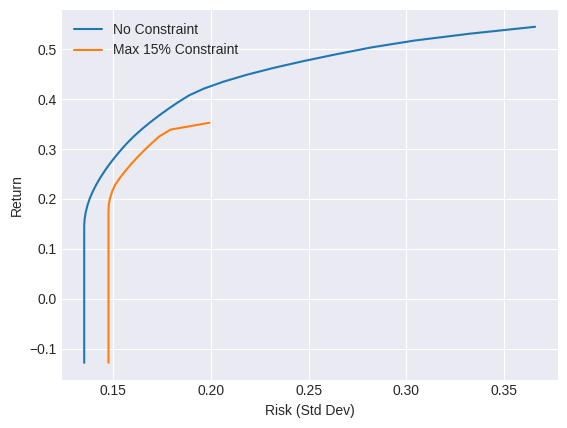

In [ ]:
# Part 1 – Step 3: Efficient Frontier Comparison
def efficient_frontier(mean_returns, cov_matrix, max_weight=None):
    frontier_returns, frontier_risks = [], []
    for r in np.linspace(mean_returns.min(), mean_returns.max(), 50):
        w = cp.Variable(n)
        constraints = [cp.sum(w) == 1, w >= 0]
        if max_weight: constraints.append(w <= max_weight)
        prob = cp.Problem(cp.Minimize(cp.quad_form(w, cov_matrix.values)),
                          constraints + [mean_returns.values @ w >= r])
        prob.solve()
        frontier_returns.append(r)
        frontier_risks.append(np.sqrt(prob.value))
    return frontier_returns, frontier_risks

fr1, risk1 = efficient_frontier(mean_returns, cov_matrix)
fr2, risk2 = efficient_frontier(mean_returns, cov_matrix, max_weight=0.15)

plt.plot(risk1, fr1, label="No Constraint")
plt.plot(risk2, fr2, label="Max 15% Constraint")
plt.xlabel("Risk (Std Dev)")
plt.ylabel("Return")
plt.legend()
plt.show()


**Out-of-Sample Performance (Step 4)**

In [ ]:
def portfolio_performance(weights, returns_test):
    port_returns = (returns_test.values @ weights)
    return pd.Series(port_returns, index=returns_test.index)

perf1 = portfolio_performance(weights_step1.values, returns_test)
perf2 = portfolio_performance(weights_step2.values, returns_test)

print("Out-of-Sample Annualized Return (Step 1):", perf1.mean()*252)
print("Out-of-Sample Annualized Return (Step 2):", perf2.mean()*252)


Out-of-Sample Annualized Return (Step 1): 0.3149370275374182
Out-of-Sample Annualized Return (Step 2): 0.3414314080043055


In [ ]:
# Function to calculate Maximum Drawdown
def max_drawdown(returns):
    cumulative_returns = (1 + returns).cumprod()
    peak = cumulative_returns.expanding(min_periods=1).max()
    drawdown = (cumulative_returns - peak) / peak
    return drawdown.min()

# --- Calculate S&P 500 Benchmark Metrics ---
# Download S&P 500 data for the test period
sp500_data = yf.download("^GSPC", start=start_date_test, end=end_date_test, progress=False)["Close"]
sp500_returns = sp500_data.pct_change().dropna()

# Calculate metrics for S&P 500
sp500_total_return_3month = ((1 + sp500_returns).prod() - 1).item()
sp500_annualized_return = (sp500_returns.mean() * 252).item()
sp500_annualized_volatility = (sp500_returns.std() * np.sqrt(252)).item()
sp500_sharpe_ratio = ((sp500_annualized_return - rf_daily * 252) / sp500_annualized_volatility).item()
sp500_max_drawdown = max_drawdown(sp500_returns).item()

# --- Gather Portfolio Metrics (Out-of-Sample) ---

# Unconstrained Portfolio (Step 1)
total_return_1 = (1 + perf1).prod() - 1
annualized_return_1 = ret1
volatility_3month_1 = perf1.std() * np.sqrt(len(perf1)) # Period volatility
sharpe_ratio_1 = sharpe1
max_drawdown_1 = max_drawdown(perf1)

# 15% Constrained Portfolio (Step 2)
total_return_2 = (1 + perf2).prod() - 1
annualized_return_2 = ret2
volatility_3month_2 = perf2.std() * np.sqrt(len(perf2)) # Period volatility
sharpe_ratio_2 = sharpe2
max_drawdown_2 = max_drawdown(perf2)

# --- Create Performance Summary Table ---
performance_summary = pd.DataFrame({
    "Performance Metric": [
        "Total Return (3-month)",
        "Annualized Return",
        "Volatility (3-month)",
        "Sharpe Ratio",
        "Maximum Drawdown",
        "vs Benchmark"
    ],
    "Unconstrained": [
        f"{total_return_1:.2%}",
        f"{annualized_return_1:.2%}",
        f"{volatility_3month_1:.2%}",
        f"{sharpe_ratio_1:.2f}",
        f"{max_drawdown_1:.2%}",
        f"{(annualized_return_1 - sp500_annualized_return) * 10000:.0f} bps"
    ],
    "15% Constrained": [
        f"{total_return_2:.2%}",
        f"{annualized_return_2:.2%}",
        f"{volatility_3month_2:.2%}",
        f"{sharpe_ratio_2:.2f}",
        f"{max_drawdown_2:.2%}",
        f"{(annualized_return_2 - sp500_annualized_return) * 10000:.0f} bps"
    ],
    "S&P 500 Benchmark": [
        f"{sp500_total_return_3month:.2%}",
        f"{sp500_annualized_return:.2%}",
        f"{sp500_annualized_volatility:.2%}", # Using annualized for benchmark consistency
        f"{sp500_sharpe_ratio:.2f}",
        f"{sp500_max_drawdown:.2%}",
        "—"
    ]
})

print("Out-of-Sample Portfolio Performance\n")
print(performance_summary.to_markdown(index=False))

print("\nNote: Volatility (3-month) for portfolios is the standard deviation of daily returns over the 3-month period. For S&P 500, annualized volatility is used for consistency in reporting annual rates.")

Out-of-Sample Portfolio Performance

| Performance Metric     | Unconstrained   | 15% Constrained   | S&P 500 Benchmark   |
|:-----------------------|:----------------|:------------------|:--------------------|
| Total Return (3-month) | 7.94%           | 8.61%             | 7.47%               |
| Annualized Return      | 31.49%          | 34.14%            | 29.69%              |
| Volatility (3-month)   | 4.68%           | 5.29%             | 8.79%               |
| Sharpe Ratio           | 2.85            | 2.77              | 2.83                |
| Maximum Drawdown       | -2.31%          | -3.39%            | -2.38%              |
| vs Benchmark           | 180 bps         | 445 bps           | —                   |

Note: Volatility (3-month) for portfolios is the standard deviation of daily returns over the 3-month period. For S&P 500, annualized volatility is used for consistency in reporting annual rates.


/tmp/ipython-input-1188674362.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500_data = yf.download("^GSPC", start=start_date_test, end=end_date_test, progress=False)["Close"]


**Fama-French 5-Factor Regression (Steps 5–6)**

/tmp/ipython-input-3038456453.py:19: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  ff_data_raw = web.DataReader('F-F_Research_Data_5_Factors_2x3_daily', 'famafrench',


Correlation Matrix of Fama-French Factors:
           MKT_RF       SMB       HML       RMW       CMA
MKT_RF  1.000000 -0.053282 -0.167896 -0.211286 -0.345303
SMB    -0.053282  1.000000  0.148050 -0.281116  0.024003
HML    -0.167896  0.148050  1.000000  0.064658  0.541820
RMW    -0.211286 -0.281116  0.064658  1.000000  0.116961
CMA    -0.345303  0.024003  0.541820  0.116961  1.000000


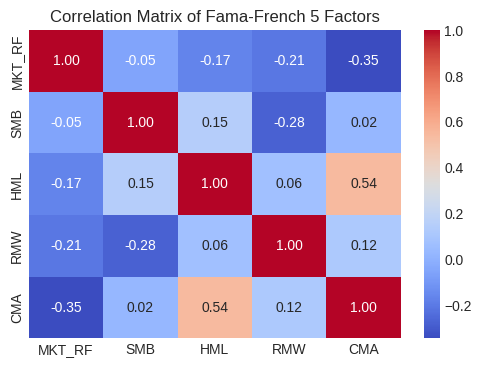

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.579
Model:                            OLS   Adj. R-squared:                  0.522
Method:                 Least Squares   F-statistic:                     34.85
Date:                Thu, 12 Feb 2026   Prob (F-statistic):           5.06e-13
Time:                        09:18:55   Log-Likelihood:                 171.86
No. Observations:                  43   AIC:                            -331.7
Df Residuals:                      37   BIC:                            -321.1
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0002      0.001      0.196      0.8

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.496
Model:                            OLS   Adj. R-squared:                  0.451
Method:                 Least Squares   F-statistic:                     45.11
Date:                Thu, 12 Feb 2026   Prob (F-statistic):           1.98e-18
Time:                        09:18:55   Log-Likelihood:                 243.89
No. Observations:                  62   AIC:                            -475.8
Df Residuals:                      56   BIC:                            -463.0
Df Model:                           5                                         
Covariance Type:                  HAC                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0002      0.001      0.271      0.787      -0.001       0.002
MKT_RF         0.6707      0.123      5.432      0.000       0.429       0.913
SMB            0.1109      0.142      0.783      0.434      -0.167       0.389
HML            0.3350      0.107      3.134      0.002       0.125       0.544
RMW            0.0636      0.136      0.468      0.640      -0.203       0.330
CMA           -0.3326      0.329     -1.010      0.312      -0.978       0.313
==============================================================================
Omnibus:                        4.388   Durbin-Watson:                   1.759
Prob(Omnibus):                  0.111   Jarque-Bera (JB):                3.770
Skew:                          -0.367   Prob(JB):                        0.152
Kurtosis:                       3.960   Cond. No.                         388.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity and autocorrelation robust (HAC) using 5 lags and without small sample correction
"""

In [ ]:
# Download Fama-French factors (Kenneth French Data Library CSV)
# The previous error 'FileNotFoundError' indicated that the CSV file was not present.
# We will use pandas_datareader to fetch the Fama-French 5 factors directly from the web.

# Install pandas_datareader if not already installed
try:
    import pandas_datareader.data as web
except ImportError:
    !pip install pandas_datareader
    import pandas_datareader.data as web

# Define start and end dates for Fama-French data, covering the range of our portfolio data
# The portfolio data covers up to '2025-09-30'.
ff_start_date = '1926-07-01' # Fama-French data typically starts much earlier
ff_end_date = '2025-09-30' # Ensure it covers the end of our test period

# Fetch Fama-French 5 factors daily data
# The 'famafrench' reader returns a dictionary of DataFrames; index [0] is the daily factors.
ff_data_raw = web.DataReader('F-F_Research_Data_5_Factors_2x3_daily', 'famafrench',
                             start=ff_start_date, end=ff_end_date)
ff_factors = ff_data_raw[0]

# Fama-French factors are usually in percentages; convert to decimal
ff_factors = ff_factors / 100

# Rename columns and set index name for consistency
ff_factors = ff_factors.rename(columns={"Mkt-RF":"MKT_RF"})
ff_factors.index.name = 'Date' # Ensure the index is named 'Date' for proper alignment
# Correlation matrix of Fama-French 5 factors
corr_matrix = ff_factors[["MKT_RF", "SMB", "HML", "RMW", "CMA"]].corr()
print("Correlation Matrix of Fama-French Factors:\n", corr_matrix)

# Optional: heatmap visualization
import seaborn as sns
plt.figure(figsize=(6,4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Fama-French 5 Factors")
plt.show()

# Align with portfolio returns (perf2)
aligned = pd.concat([perf2, ff_factors], axis=1).dropna()

# The risk-free rate rf_daily is a Series with a single value, extract it as a scalar.
rf_daily_scalar = rf_daily.iloc[0]

X = aligned[["MKT_RF","SMB","HML","RMW","CMA"]]
y = aligned.iloc[:,0] - rf_daily_scalar # Subtract scalar rf_daily from aligned portfolio returns
X = sm.add_constant(X)

# Step 5 (Train/Test Split)Train/Test split for regression
train_size = int(0.7 * len(aligned))  # 70% train, 30% test
train_data = aligned.iloc[:train_size]
test_data = aligned.iloc[train_size:]

X_train = sm.add_constant(train_data[["MKT_RF", "SMB", "HML", "RMW", "CMA"]])
y_train = train_data.iloc[:,0] - rf_daily_scalar

X_test = sm.add_constant(test_data[["MKT_RF", "SMB", "HML", "RMW", "CMA"]])
y_test = test_data.iloc[:,0] - rf_daily_scalar

# Fit OLS on training data
model_train = sm.OLS(y_train, X_train).fit(cov_type="HAC", cov_kwds={"maxlags":5})
print(model_train.summary())

# Evaluate on test data
y_pred = model_train.predict(X_test)
test_r2 = 1 - np.sum((y_test - y_pred)**2) / np.sum((y_test - y_test.mean())**2)
print("Test R-squared:", test_r2)

# Fit the OLS model
model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags":5})
model.summary()


In [ ]:
# Calculate summary statistics for Fama-French factors
ff_summary_stats = pd.DataFrame({
    "Mean (%)": ff_factors[["MKT_RF", "SMB", "HML", "RMW", "CMA"]].mean() * 100,
    "Std Dev (%)": ff_factors[["MKT_RF", "SMB", "HML", "RMW", "CMA"]].std() * 100,
    "Skewness": ff_factors[["MKT_RF", "SMB", "HML", "RMW", "CMA"]].skew(),
    "Kurtosis": ff_factors[["MKT_RF", "SMB", "HML", "RMW", "CMA"]].kurt()
})

# Format the table
ff_summary_stats.index.name = "Factor"
ff_summary_stats = ff_summary_stats.reset_index()

print("Factor Summary Statistics\n")
print(ff_summary_stats.to_markdown(index=False, floatfmt=".2f"))

Factor Summary Statistics

| Factor   |   Mean (%) |   Std Dev (%) |   Skewness |   Kurtosis |
|:---------|-----------:|--------------:|-----------:|-----------:|
| MKT_RF   |       0.03 |          1.02 |      -0.49 |      15.66 |
| SMB      |       0.01 |          0.55 |      -0.56 |      16.48 |
| HML      |       0.01 |          0.59 |       0.27 |      10.42 |
| RMW      |       0.01 |          0.40 |       0.32 |       8.57 |
| CMA      |       0.01 |          0.38 |      -0.24 |       7.25 |


**Simulation vs Optimization (Steps 7)**

In [ ]:
subset = ["TSLA","WMT","BAC","AAPL","XOM"]
returns_sub = returns_in[[f"{t}_AdjClose" for t in subset]]

# Optimization
mean_sub = returns_sub.mean()*252
cov_sub = returns_sub.cov()*252
w_sub = cp.Variable(len(subset))
constraints_sub = [cp.sum(w_sub)==1, w_sub>=0]
prob_sub = cp.Problem(cp.Minimize(cp.quad_form(w_sub, cov_sub.values)),
                      constraints_sub + [mean_sub.values @ w_sub >= mean_sub.mean()])
prob_sub.solve()
weights_opt = pd.Series(w_sub.value, index=subset)

# Simulation
N = 100000
rand_weights = np.random.dirichlet(np.ones(len(subset)), N)
returns_sim = rand_weights @ mean_sub.values
risks_sim = np.sqrt(np.einsum("ij,jk,ik->i", rand_weights, cov_sub.values, rand_weights))
best_idx = np.argmax(returns_sim/risks_sim)
weights_sim = pd.Series(rand_weights[best_idx], index=subset)

print("Optimization Weights:\n", weights_opt)
print("Simulation Weights:\n", weights_sim)


Optimization Weights:
 TSLA    2.434790e-23
WMT     4.322292e-01
BAC     9.980102e-02
AAPL    1.189283e-01
XOM     3.490414e-01
dtype: float64
Simulation Weights:
 TSLA    0.006408
WMT     0.656882
BAC     0.316804
AAPL    0.002205
XOM     0.017702
dtype: float64


**Optimization with 30% max constraint (Step 8)**

In [ ]:
# Step 8: Optimization with 30% max constraint
constraints_step8 = [cp.sum(w_sub) == 1, w_sub >= 0, w_sub <= 0.3]
prob_step8 = cp.Problem(cp.Minimize(cp.quad_form(w_sub, cov_sub.values)),
                        constraints_step8 + [mean_sub.values @ w_sub >= mean_sub.mean()])
prob_step8.solve()
weights_opt_step8 = pd.Series(w_sub.value, index=subset)
print("Step 8 Optimization Weights:\n", weights_opt_step8)

# Step 8: Simulation with 30% max constraint
N = 200000
rand_weights = np.random.dirichlet(np.ones(len(subset)), N)
# Apply 30% cap
rand_weights = rand_weights[(rand_weights <= 0.3).all(axis=1)]
returns_sim_step8 = rand_weights @ mean_sub.values
risks_sim_step8 = np.sqrt(np.einsum("ij,jk,ik->i", rand_weights, cov_sub.values, rand_weights))
best_idx_step8 = np.argmax(returns_sim_step8 / risks_sim_step8)
weights_sim_step8 = pd.Series(rand_weights[best_idx_step8], index=subset)
print("Step 8 Simulation Weights:\n", weights_sim_step8)


Step 8 Optimization Weights:
 TSLA   -2.960423e-23
WMT     3.000000e-01
BAC     2.551329e-01
AAPL    1.448671e-01
XOM     3.000000e-01
dtype: float64
Step 8 Simulation Weights:
 TSLA    0.023674
WMT     0.293356
BAC     0.295766
AAPL    0.111125
XOM     0.276079
dtype: float64
